# Hierarchical Clustering - UPGMA

In [1]:
%pip install numpy matplotlib biopython

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from typing import List, Tuple, Dict
from io import StringIO

import matplotlib.pyplot as plt
from Bio import Phylo
import numpy as np

---
## Distance metrics for comparing sequences

### Smith-Waterman
This was previously implemented. Feel free to import if you know how...or Copy & Paste.



In [3]:
def read_fasta(filename: str) -> Dict[str, str]:
    """Reads sequences from FASTA file.

    Args:
        filename (str): Path to FASTA file containing HIV RT sequences

    Returns:
        Dict[str, str]: Dictionary mapping sequence IDs to sequences

    Examples:
        >>> seqs = read_fasta("lafayette_SARS_RT.fasta")
        >>> len(seqs) > 0
        True
    """
    #sequences = empty dictionary (name to sequence)
    sequences = {}

    #current_name = nothing yet
    current_name = None

    #Open the file and read it line by line:
    with open(filename) as file:
        for line in file:
        #strip spaces and the newline off the end of the line
            line = line.strip()
            
            #IF the line is empty:
                #skip it
            if line == "":
                continue

            #IF the line starts with ">":
            if line.startswith (">"):
                #current_name = last word of the line (i.e. "DM1")
                current_name = line.split()[-1]
                #sequences[current_name] = empty string
                sequences[current_name] = ""

            #ELSE (it's part of a sequence):
            else:
                #add the line to the end of sequences[current_name]
                sequences[current_name] = sequences[current_name] + line

    #Return sequences
    return sequences 

In [4]:
def cal_score(matrix, seq1, seq2, i, j, match, mismatch, gap):
    '''Calculate score for position (i,j) in scoring matrix, also record move to trace back
    
    Args:
        matrix (numpy array): scoring matrix
        seq1 (str): sequence 1
        seq2 (str): sequence 2
        i (int): current row number
        j (int): current column number
        
    Returns:
        score in position (i,j)    
        move to trace back: 0-END, 1-DIAG, 2-UP, 3-LEFT
        
    Pseudocode:
        Calculate scores based on upper-left, up, and left neighbors:
            diag_score = upper-left + (match or mismatch)
            up_score = up + gap
            left_score = left + gap
        score = max(0, diag_score, up_score, left_score)
        traceback = maximum direction or end
        
    '''
    #Determine match or mismatch
    if seq1[i - 1] == seq2[j - 1]:
        match_score = match
    else:
        match_score = mismatch

    #CALCULATE PATH SCORES GROM THE PREDECESSORS
    diag_score = matrix[i - 1, j - 1] + match_score
    up_score   = matrix[i - 1, j] + gap
    left_score = matrix[i, j - 1] + gap

    #COMPUTE SCORE EITH THE ZERO THRESHOLD
    score = max(0, diag_score, up_score, left_score)

    # RECORD TRACEBACK DIRECTION
    if score == 0:
        move = 0
    elif score == diag_score:
        move = 1
    elif score == up_score:
        move = 2
    else:
        move = 3

    return score, move

In [5]:
def smith_waterman(
    sequence1: str,
    sequence2: str,
    match_score: float = 2.0,
    mismatch_penalty: float = -1.0,
    gap_penalty: float = -1.0
) -> float:
    """Implements Smith-Waterman local alignment algorithm.

    Args:
        sequence1 (str): First HIV RT sequence
        sequence2 (str): Second HIV RT sequence
        match_score (float): Score for matching characters
        mismatch_penalty (float): Penalty for mismatched characters
        gap_penalty (float): Penalty for gaps

    Returns:
        float: Normalized similarity score between sequences

    Examples:
        >>> seq1 = "ACGT"
        >>> seq2 = "ACGT"
        >>> smith_waterman(seq1, seq2)
        1.0
    """
    n, m = len(sequence1), len(sequence2)
    if n == 0 or m == 0:
        return 0.0

    matrix = np.zeros((n + 1, m + 1))
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            score, _ = cal_score(matrix, sequence1, sequence2, i, j,
                                 match_score, mismatch_penalty, gap_penalty)
            matrix[i, j] = score

    # Best local score, scaled by a perfect match of the shorter sequence
    return float(matrix.max() / (match_score * min(n, m))) 
    

In [6]:
def build_distance_matrix(sequences: Dict[str, str]) -> Tuple[np.ndarray, List[str]]:
    """Builds DISTANCE (not similiarity) matrix using Smith-Waterman scores.

    Args:
        sequences (Dict[str, str]): Dictionary of HIV RT sequences

    Returns:
        Tuple[np.ndarray, List[str]]: Distance matrix and list of sequence IDs

    Examples:
        >>> seqs = read_fasta("lafayette_SARS_RT.fasta")
        >>> mat, ids = build_distance_matrix(seqs)
        >>> mat[0:3, 0:3]  # Show 3x3 slice of distance matrix
        array([[0.000, 0.004, 0.012],
              [0.004, 0.000, 0.012],
              [0.012, 0.012, 0.000]])
        >>> len(ids)  # Number of sequences
        19
    """

    #ids = list of the sequence names, in file order (i.e. ["DM1", "DM2", ...])
    ids = list(sequences.keys())

    #n = number of sequences
    n = len(ids)

    #distance_matrix = n x n grid of zeros (diagonal stays 0: each sequence vs itself)
    distance_matrix = np.zeros((n, n))

    #For each row i from 0 to n-1:
    for i in range(n):
        #FOR each column j from i+1 to n-1 (only pairs not yet done; skip the diagonal):
        for j in range(i + 1, n):
            #similarity = smith_waterman (sequence for ids[i], sequence for ids[j])
            similarity = smith_waterman(sequences[ids[i]], sequences[ids[j]])
            distance = 1 - similarity
            distance_matrix[i, j] = distance
            distance_matrix[j, i] = distance  #Table is symmetric, so fill both halves

    return distance_matrix, ids

In [7]:
def neighbor_joining(
    distance_matrix: np.ndarray,
    labels: List[str]
) -> str:
    """Implements Neighbor-Joining algorithm for phylogenetic tree construction.

    Args:
        distance_matrix (np.ndarray): Distance matrix from Smith-Waterman scores
        labels (List[str]): Sequence identifiers

    Returns:
        str: Newick format tree string

    Examples:
        >>> seqs = read_fasta("lafayette_SARS_RT.fasta")
        >>> mat, ids = build_distance_matrix(seqs)
        >>> tree = neighbor_joining(mat, ids)
        >>> tree.startswith("((DM1:0.002,DM2:0.002)")  # Start of Newick string
        True
        >>> tree.count(",")  # Number of separators in tree
        18
    """
    D = distance_matrix.copy()
    current_labels = labels.copy()
    n = len(D)

    while n > 2:
        totals = [sum(row) for row in D]
        lowest_score = float('inf')

        # D* score for each pair
        for i in range(n):
            for j in range(i+1, n):
                score = (n-2) * D[i,j] - totals[i] - totals[j]
                if score < lowest_score:
                    lowest_score = score
                    best_i = i
                    best_j = j

        # Branch lengths for best_i and best_j
        branch_i = (D[best_i, best_j] + (totals[best_i] - totals[best_j]) / (n-2)) / 2
        branch_j = D[best_i, best_j] - branch_i
        if branch_i < 0:
            branch_i = 0
            branch_j = D[best_i, best_j]
        elif branch_j < 0:
            branch_j = 0
            branch_i = D[best_i, best_j]

        # Distance from new node to every other node
        new_distances = []
        for k in range(n):
            if k == best_i or k == best_j:
                continue
            new_distances.append((D[best_i, k] + D[best_j, k] - D[best_i, best_j]) / 2)
        new_label = f"({current_labels[best_i]}:{branch_i:.4f},{current_labels[best_j]}:{branch_j:.4f})"

        # Shrink the table
        keep = [k for k in range(n) if k not in (best_i, best_j)]
        D = np.pad(D[np.ix_(keep, keep)], (0, 1)) # D = matrix with rows and cols in keep plus an extra row and column of 0s
        D[-1, :-1] = D[:-1, -1] = new_distances # set last row and col with new distances
        current_labels = [current_labels[k] for k in keep] + [new_label]

        n = len(D) 

    # Exactly 2 nodes left
    final_distance = D[0, 1] / 2
    tree = f"({current_labels[0]}:{final_distance:.4f},{current_labels[1]}:{final_distance:.4f});"
    return tree

In [8]:
def plot_tree(newick_tree: str) -> None:
    """Plots a phylogenetic tree from a Newick string using Biopython and Matplotlib.

    The tree is rendered in a rectangular layout with smaller leaf labels and
    added margins to reduce overlap between labels and branches.

    Args:
        newick_tree (str): Tree in Newick format

    Returns:
        None: Displays the plotted tree
    """
    handle = StringIO(newick_tree)
    tree = Phylo.read(handle, "newick")

    fig, ax = plt.subplots(figsize=(8, 10))

    Phylo.draw(
        tree,
        axes=ax,
        do_show=False,
        label_func=lambda clade: clade.name if clade.is_terminal() else None,
    )
    for text in ax.texts:
        text.set_fontsize(6)              # shrink labels
    ax.margins(x=0.1, y=0.05)             # extra padding around tree

    plt.tight_layout()
    plt.savefig("nj_tree.png", dpi=200, bbox_inches="tight") #shows figure to link results image output to README.md
    plt.show()


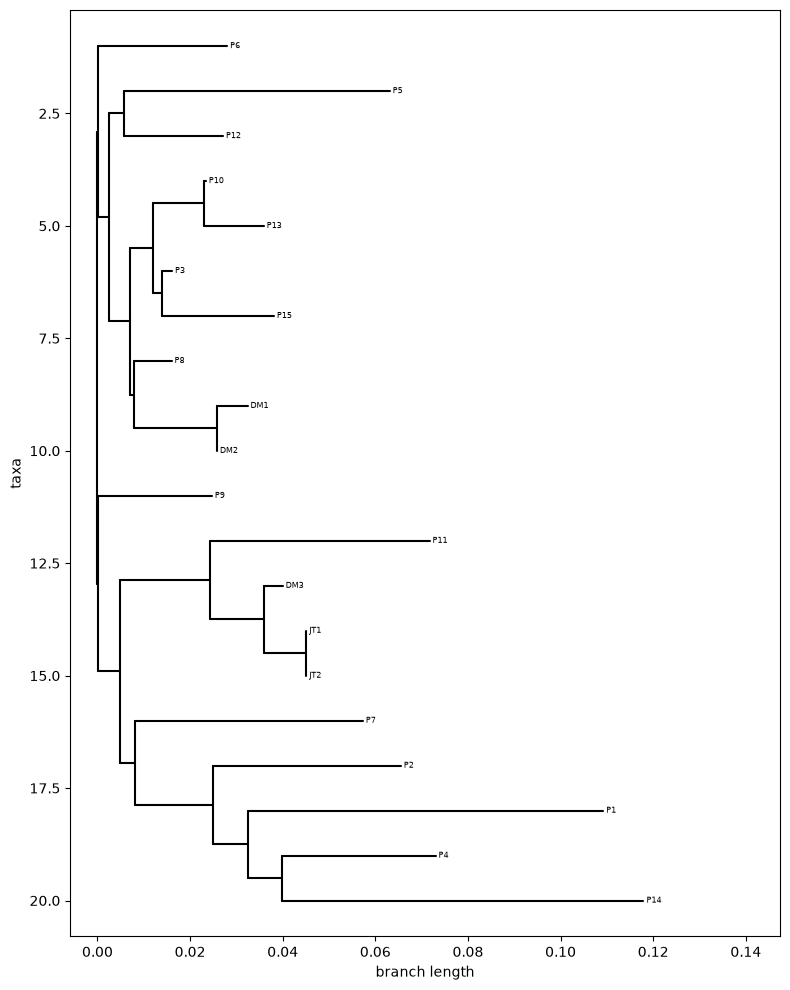

In [9]:
if __name__ == "__main__":
    # Read HIV RT sequences
    sequences = read_fasta("lafayette_SARS_RT.fasta")
    
    # Build distance matrix using Smith-Waterman
    dist_matrix, seq_ids = build_distance_matrix(sequences)
    
    # Generate unrooted tree using Neighbor-Joining
    tree = neighbor_joining(dist_matrix, seq_ids)
    
    # Plot tree
    plot_tree(tree)